<a href="https://colab.research.google.com/github/dangngocthu033/CS467A/blob/main/RecSys_29211154628.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS467 - Advanced Artificial Intelligence
## Assignment 14 - Recommendation Systems I: a basic recommender
**Section A (CS467A) - Duy Tan University - 2026-2027**
**Instructor: Puri Vikram**

---

### Your studio - Hải Châu Roast (Da Nang)

Session 13 showed how a recommender turns a sparse table of ratings into a
short, ranked list. In this assignment you **build that recommender yourself**,
in NumPy, step by step: from the raw ratings log to a tested top-3 list.

You have just joined **Hải Châu Roast** as their **data scientist**. They want a
**Drink Picker** that can **suggest a drink each regular has not tried yet**. You get their ratings log:
**8 customers**, **10 drinks**, stars from 1 to 5, and a small feature table
(`coffee`, `sweet`, `iced`, `tea`). Most cells of the user-item matrix are empty.

Your **target customer** is **An**. Your **focus drink** is **Iced Milk Coffee**,
which An has never rated. Many questions ask what *your* recommender
does for *that* customer.

The six situations:

| # | Situation | Difficulty | What you do |
|---|-----------|-----------|-------------|
| 1 | The user-item matrix | Easy | build the matrix from the log, sparsity, means, a heatmap |
| 2 | Popularity baseline | Easy-Med | item statistics, a minimum-count rule, top-3 for An |
| 3 | Content-based | Medium | An's **taste profile** from features, cosine scores, top-3 |
| 4 | Customers like you | Medium-Hard | **cosine** and **Pearson** similarity over co-rated drinks, neighbours |
| 5 | Predict and recommend | Hard | neighbour-based **rating prediction**, collaborative top-3 |
| 6 | Did it work? | Hard / stretch | **RMSE / MAE / precision@3** on hidden ratings, a memo |

### How this notebook works (read carefully)
1. This notebook is **personalized to you**. Your **Student ID** and **name**
   are already filled in. They seed **your studio, your customers, every
   rating, your hidden test set, your target customer, your focus drink,
   `K` and `MIN_COUNT`**. **No two students have the same data.** An answer
   written for someone else's data will fail the self-checks.
2. Cells that are **greyed-out / locked** (instructions and helper code)
   **cannot be edited or deleted**. You only write code where you see
   **`# YOUR CODE HERE`** / **`TODO`**.
3. After each situation there is a **Self-check** cell. It is **not a grade**.
   It tells you *which* answers are still wrong, never the correct values.
4. The **last cell** prints your **SUBMISSION CODE** - unique to you.

### One rule for every ranking
Whenever you sort drinks or customers by a score, sort **high to low** and
break ties by the **lower index** (popularity breaks ties by the number of
ratings first). In Python: `sorted(candidates, key=lambda i: (-score[i], i))`.
Avoid `np.argsort` for rankings: it does not promise this tie order.

### Academic-integrity note
Pasting a generic answer from an AI chatbot **will not work here**: every
number depends on *your* ratings, and the written answers must talk about
*your* customer An and *your* drinks. Write your own code. You may discuss
ideas, but the code and the written answers must be yours. Be ready to explain
*your* neighbours and *your* top-3 list in a viva.

### How to start
**File -> Save a copy in Drive**, then work in *your* copy. Run cells top to
bottom with **Shift+Enter**. Use **NumPy** (`np`) and plain Python - no
scikit-learn, no recommender libraries.


## Setup - run this first (locked)

In [38]:
#@title Setup: import libraries (run me) { display-mode: "form" }
# Locked helper cell - do not edit.
import math, random, hashlib, json
import numpy as np                 # pre-installed on Google Colab
import matplotlib.pyplot as plt    # pre-installed on Google Colab
np.set_printoptions(precision=4, suppress=True)
print("Libraries loaded. numpy", np.__version__)


Libraries loaded. numpy 2.4.6


## Step 0 - Your identity (already filled in - just run it)

This notebook belongs to **you**. Your Student ID and name are already filled in
and **locked** below - you cannot change them, and they seed your data.
Just run this cell, then continue.

In [39]:
#@title Your identity - already filled in, just run { display-mode: "form" }
# This cell is locked. It is personalised for you and cannot be edited.
STUDENT_ID = "29211154628"  #@param {type:"string"}
FULL_NAME  = "Lê Đỗ Nguyên Vũ"  #@param {type:"string"}
SECTION    = "CS467A"   # fixed for your class - do not change

STUDENT_ID = STUDENT_ID.strip()
FULL_NAME  = FULL_NAME.strip()
assert STUDENT_ID != "" and FULL_NAME != "", "Please fill in BOTH your Student ID and your name."

_masked = STUDENT_ID[:2] + "***" + STUDENT_ID[-2:] if len(STUDENT_ID) >= 4 else STUDENT_ID
print(f"Welcome to the studio, {FULL_NAME}  |  Section {SECTION}  |  ID {_masked}")
print("Run the next cell to load YOUR ratings world.")


Welcome to the studio, Lê Đỗ Nguyên Vũ  |  Section CS467A  |  ID 29***28
Run the next cell to load YOUR ratings world.


## Your data - **Drink Picker** at **Hải Châu Roast** (locked helper)

Run this once. It loads *your* customers, *your* ratings and *your* hidden test
set. You never re-type the numbers - you write the **algorithms**.

Locked names you will use:

- `USERS` - the 8 customer names (row order); `ITEMS` - the 10 drink names (column order)
- `FEATURES` - the 4 feature names; `ITEM_FEATURES` - a `(10, 4)` 0/1 NumPy array
- `RATINGS` - the training log: a list of `(user, item, stars)` tuples, in random order
- `TEST` - hidden `(user, item, stars)` tuples, **not** in `RATINGS` (Situation 6 only)
- `TARGET_USER` / `TARGET` - your target customer **An** and their row index
- `FOCUS_ITEM` / `FOCUS` - your focus drink **Iced Milk Coffee** and its column index
- `K` - how many neighbours a prediction uses; `MIN_COUNT` - the popularity threshold
- `TOP_N = 3` - every recommendation list has 3 drinks; `REL_THRESHOLD = 4`


In [40]:
#@title Your ratings world - Drink Picker at Hải Châu Roast (run me) { display-mode: "form" }
# Locked helper cell - do not edit. This is YOUR data only.
import numpy as np
STUDIO_KEY = "cafe"
STUDIO_TITLE = "Drink Picker"
COMPANY = "Hải Châu Roast"
GOAL = "suggest a drink each regular has not tried yet"
NOUN = "drink"

USERS = ["Minh", "Lan", "An", "Ngoc", "Khoa", "Phuc", "Dung", "Binh"]            # row order of the user-item matrix
ITEMS = ["Iced Milk Coffee", "Egg Coffee", "Black Coffee", "Salt Coffee", "Coconut Coffee", "Lotus Tea", "Peach Iced Tea", "Hot Ginger Tea", "Cold Brew", "Matcha Latte"]
FEATURES = ["coffee", "sweet", "iced", "tea"]

# ITEM_FEATURES[i][f] = 1 if item i has feature f (columns follow FEATURES)
ITEM_FEATURES = np.array([
    [1, 1, 1, 0],   # Iced Milk Coffee
    [1, 1, 0, 0],   # Egg Coffee
    [1, 0, 0, 0],   # Black Coffee
    [1, 1, 1, 0],   # Salt Coffee
    [1, 1, 1, 0],   # Coconut Coffee
    [0, 0, 0, 1],   # Lotus Tea
    [0, 1, 1, 1],   # Peach Iced Tea
    [0, 0, 0, 1],   # Hot Ginger Tea
    [1, 0, 1, 0],   # Cold Brew
    [0, 1, 0, 1],   # Matcha Latte
])

# The ratings log (training data): (user, item, stars 1-5). Order is random.
RATINGS = [
    ("Binh", "Peach Iced Tea", 4),
    ("Minh", "Hot Ginger Tea", 5),
    ("Dung", "Coconut Coffee", 3),
    ("Phuc", "Lotus Tea", 4),
    ("Binh", "Cold Brew", 5),
    ("An", "Salt Coffee", 4),
    ("Binh", "Egg Coffee", 5),
    ("Minh", "Matcha Latte", 3),
    ("Lan", "Cold Brew", 4),
    ("Binh", "Hot Ginger Tea", 3),
    ("Minh", "Salt Coffee", 3),
    ("Binh", "Coconut Coffee", 5),
    ("Lan", "Hot Ginger Tea", 5),
    ("An", "Cold Brew", 5),
    ("Lan", "Iced Milk Coffee", 4),
    ("Dung", "Lotus Tea", 5),
    ("Lan", "Lotus Tea", 5),
    ("Khoa", "Egg Coffee", 1),
    ("Dung", "Egg Coffee", 1),
    ("An", "Egg Coffee", 4),
    ("Lan", "Coconut Coffee", 4),
    ("Phuc", "Egg Coffee", 2),
    ("Ngoc", "Egg Coffee", 5),
    ("Minh", "Peach Iced Tea", 4),
    ("Khoa", "Iced Milk Coffee", 2),
    ("Phuc", "Black Coffee", 1),
    ("Phuc", "Hot Ginger Tea", 4),
    ("Khoa", "Lotus Tea", 5),
    ("Dung", "Salt Coffee", 2),
    ("Phuc", "Coconut Coffee", 3),
    ("Dung", "Cold Brew", 3),
    ("Dung", "Peach Iced Tea", 4),
    ("Dung", "Iced Milk Coffee", 3),
    ("Ngoc", "Matcha Latte", 4),
    ("Ngoc", "Iced Milk Coffee", 5),
    ("Binh", "Salt Coffee", 5),
    ("Binh", "Lotus Tea", 2),
    ("Lan", "Salt Coffee", 3),
    ("An", "Black Coffee", 5),
    ("Minh", "Black Coffee", 1),
    ("Khoa", "Salt Coffee", 2),
    ("Ngoc", "Hot Ginger Tea", 3),
    ("Phuc", "Peach Iced Tea", 4),
    ("Khoa", "Peach Iced Tea", 3),
    ("Minh", "Egg Coffee", 2),
    ("Binh", "Matcha Latte", 3),
    ("Ngoc", "Salt Coffee", 5),
    ("Khoa", "Cold Brew", 3),
    ("An", "Matcha Latte", 3),
    ("Phuc", "Cold Brew", 4),
    ("Minh", "Cold Brew", 3),
    ("Lan", "Black Coffee", 1),
    ("Phuc", "Matcha Latte", 3),
]

# Hidden test ratings - NOT in RATINGS. Use them only in Situation 6.
TEST = [
    ("An", "Peach Iced Tea", 4),
    ("An", "Coconut Coffee", 4),
    ("An", "Hot Ginger Tea", 3),
    ("Khoa", "Coconut Coffee", 3),
    ("Lan", "Egg Coffee", 2),
    ("Minh", "Lotus Tea", 4),
    ("Dung", "Hot Ginger Tea", 5),
    ("Ngoc", "Lotus Tea", 3),
]

TARGET_USER = "An"
TARGET = USERS.index(TARGET_USER)        # row index of your target customer
FOCUS_ITEM = "Iced Milk Coffee"
FOCUS = ITEMS.index(FOCUS_ITEM)          # column index of your focus item
K = 2                                  # neighbours used for a prediction
MIN_COUNT = 2                          # popularity needs at least this many ratings
TOP_N = 3                              # every recommendation list has 3 items
REL_THRESHOLD = 4                      # a test rating >= 4 means "relevant"

print("Studio      :", COMPANY, "-", STUDIO_TITLE)
print("Goal        :", GOAL)
print("Customers   :", USERS)
print("%ss%s:" % (NOUN.capitalize(), " " * max(1, 11 - len(NOUN))), ITEMS)
print("Features    :", FEATURES)
print("Ratings log :", len(RATINGS), "training ratings,", len(TEST), "hidden test ratings")
print("Target      :", TARGET_USER, "(row %d)  | focus %s: %s (column %d)" % (TARGET, NOUN, FOCUS_ITEM, FOCUS))
print("K = %d, MIN_COUNT = %d, TOP_N = %d" % (K, MIN_COUNT, TOP_N))


Studio      : Hải Châu Roast - Drink Picker
Goal        : suggest a drink each regular has not tried yet
Customers   : ['Minh', 'Lan', 'An', 'Ngoc', 'Khoa', 'Phuc', 'Dung', 'Binh']
Drinks      : ['Iced Milk Coffee', 'Egg Coffee', 'Black Coffee', 'Salt Coffee', 'Coconut Coffee', 'Lotus Tea', 'Peach Iced Tea', 'Hot Ginger Tea', 'Cold Brew', 'Matcha Latte']
Features    : ['coffee', 'sweet', 'iced', 'tea']
Ratings log : 53 training ratings, 8 hidden test ratings
Target      : An (row 2)  | focus drink: Iced Milk Coffee (column 0)
K = 2, MIN_COUNT = 2, TOP_N = 3


In [41]:
#@title Self-check engine (locked - run me) { display-mode: "form" }
# Locked helper. The self-check cells call this engine for you - you never need to read it.
import zlib as _z, base64 as _b
_ENGINE = (
    "eNq1Gv1v2zb29/wVPA+9kzbF9UfS3dKp2LBLtqJbc3BSIAfBECiZtjXLkipKib1h97ffe4+kRFl21247I7Ul8vHxfX+QPUu2RV5W"
    "LKu3xZ5xybLCY1terT32s8wzj625XKdJdHa2EEsWlmIZRnWSLpySV0m2kh6rpSjhJ6nEVrpXZww+M+YDnuGyTlPHSUXmEIzrMXxW"
    "gPACEBnPXFqxzEtWAxKPlSzJmEausBHGgFAMk2whdk7t6v30e+LOYcdlmvPKKRXCUlR1mbGZRbcseCmTau/MNJkaRq0DahIJ9MDs"
    "cCvg13XttRWvZLMwzuuskrCl819rmTuU9dbhu0T6I0UEvEslCoDAyZnH7HncR1qymg3lmhciGM+70sk3AKQ3fcVG7dog3yDnuA89"
    "PtdQ+GKzSMCenrTYKvKiTnmJdG2TLKR5zWNnCezREUNLVZCQ7hKltWwlLCZcliwNQcmcvfLbTTrUSTBAsXDyjcc2Yu+nfBstOEuu"
    "mHOuuExAHucNItB9RzeliJERZAJMKOuzorexST3NPdLcKjVAo5y78+Aqm1tbxrl0uMcivQFXOuSSlyXf48yi2hfCJ8tyX7KoOx91"
    "5wlFBosyDZcmGU9XwywvwZyUo9hDUcfCR8MRkQw0+GzEgEFEg48ilUIbN2ffABHPmQNgnwNAR35FmS+TVKAYbkCERmj5E1ADApi/"
    "RHcUC3hrrR1mFRUIBC8BgczZufWi3cgm9gnosARx0xWEXteRc1aJrAplnJdCHlBYGKs8ZMDe8Vcwo0ZlENpuwIDc3zHZnvp/O0IS"
    "WF1DEKhI0yRjQ9QJ0o/YvYz7di9jY+g9y6Mg0tqexmUFooADG3/vjERzt2u9fTzblvBm5oidbSnIuexrNlEG1ggX9w22QDRuBw8d"
    "ExO8/IQtu/u0WaAlhYZ2HtuTjXY3tqluqNuBae60ReKyc7Y/EuYzkazWFEiMPhOK4IHz6B3KDrT+6CpTeuyb0kiZ0iP7m8/qY9EO"
    "MXf0XqHeK4r9FS636aqJVIuuw9QFalYg4K8Hzi0WSVxpgiG/bkwO49nCcCY1G/DUBEdLFOQTeWX7xSP5BUMclJIgQOqMgyEfhlul"
    "NW5qMcG+wJzlSAhGBhlopAvVCFdThVhdiGFqIc6E9syhkSjRQFx3LocjLGl2zhgfCtd1dRJPyXiucPfA9pYrFfP7goYlxmhUakuH"
    "MvlFWI5g8Wg73NIKA3Wrg8MYdURZfypUUW5s8+KmH6R6hP3Z+BRxSYE4aUqlv1bKfYvv1gJb2B7CfGXlCCvhFIeZuerOV0cy86Gr"
    "yfcl/dLuTgF2C0XD55+ziduhZMv/34QQAbgmkpqMQ8+PHfgHJbVIxSPPqp7hYTkuReWkiawQ1EUvxtyBg2aVi063OTv7jJ3Dh1Vr"
    "wWRVLyC3/UOyp7xMF1glbosaa4Q8iwXBnYUzY2SqX5h9e//67fd3Hnt3dz2Dn9f31z/duWfhTZdxHA5vrr+9fze7vjsQQnh/fXcf"
    "vsOoRUiabsC0DxAQQnQVhJtr8NcITps1zYIJHskRcKQ6MJ2EAQx1W6IBZ9c/AtSvR5BaLQzCovnWWIzdfzv7/hpIB6opZpZYDAOa"
    "8P4HYPOH2x//ZfxW7AoRo9eZVgrqBhQk/IY3H1mYQ13blEZtifvT67fhd7fv3t5rICiajhdQilgdJOUH65kO6PQQ1CqRFCD83v47"
    "fKsr3sjAN6nGRhcJST4RQS6EP7XF8mjgMsjf6F5yakHpANjZv4EsCGFwPPa+aVWK+vwlKRxtgKAKZVo6ehVRg6UNf1avoYAV7Doh"
    "pRnPW07R3dCiOj5OlDQZ7W4cUtD3dfD3cCQLdZPsJ1nlHGlEscXGlbrr9Q97YM/GX/FyJaqQCvAewkBJb95FrJegOfrd3KfV2Nlg"
    "mce1VMA6M1Nnd3P73bu7uUKoQMiuiQTd8BmQFtsEmBdpskqiVPgoSbByRDEJ0WhCPBnwyTkDmADbmbdzPQI0RBd9lRdTXwUNbFy7"
    "XaPVbh5YVethcwvd1LiXr+PKTtnGDjHiFJI3DdNkIxbhUnAwAOGbCBigIDA8liusYBDcPcB+ith4qhDDvPIVP5ZBPCV5tOsvSC4+"
    "xdMAH3GRGsRa11f+N7ZGsZaXuda5VdgbYSCQ29sBgFrjsor+zqrWvC6Q7I2v4nzwODeVIMVroOnqTYeLS2086MT+oTubLciQ0K89"
    "XHBKbEsSG80rdPEyWB5K7QUVGhBffKvqiJcmMMxwCw2DEcGGiiwgGyHUCw0+qh166BCixUYwp5BhlPHxixZiJZDIBHRG0ee5tlda"
    "4OrEzqo8FVBiVpTLeZmAitlapIUoVbFNeV+ky/N4LeKNxDUqY8VpDnxh8+YhEn8izi908qrKfa95gwJSUjfxNs8EJUOsX/QxhQtl"
    "jHqMoOz42keEhEDsYlFU7Jp+gJMe2hsO1aHOoVBJ9Kgai/MXx6j6C45ubOZUgMaUH+lH5DDK85S8OE1tujgSBv+gYsAnaE7E+5qn"
    "IQRd/76shW5UPol3LOX+vEowqIIyfJWoItXoAfWORo2dN6HWoQw7ap0jqYv/A4Sjt3601kyDAhkU44lukzZIgyIbZ/pk82ADzh0F"
    "as3c4kAv/XSyC56U8lPpPileJGxHZwcwt4cHmjFCpzC8VycEf6XooYhfSEf22gOIGRkUllDS46SsSrcxDjmURZpU2KJBJbsxiMo8"
    "WzkRxR0SjMb3GXvLt0JSDIGk+4QxpVrzii1ysrstr+I1uH4mHkUJOTHByhaBTTXMHnlaCzlUlSGng4sMUJII8MHD02jMp7irOa/I"
    "2yMJWNOKAAkc8qIQ2cIZwDaypapD0H9u383Yglec7UV1xQbsCzbw2GD4c56A1rh15mB/AIhhM6VaImRjy56Sas32eV2y/AlSTJ3F"
    "qBT5kpVQ4yzw2oVLSP/uoG3g8FbGqfjKY0qe+SbcypXpJkuq0QbPJLt9A4J7JgfsGVPgGrA5tcHlqndGeGTjGQNAPIMZvGy4ASC3"
    "yQXrZAH9HZjBeQVpGdYsodJe4wnEIt+qnk/ajaBWnBTCygsIHRIsVLoCmsQsrP0X+JP4X0IYFRmVpaOh8ZRShVq1yxBw8DqFkhQs"
    "Cte7zc1SCT1XJVagLmfsMcCIpwO+A+gJOVSpXGKMdqwYPQtKjdixANkrQ8a8uaZpr6PaQxdY4V6x45/PGPK+p2swthGikOgRE3OF"
    "1ZgIaKNTU9dNOd0949S3XR67miBRwQQPrS6HugPCXtCxWYFG5YIYGQ0vjzFu7sGg/NGmlWyLNFymfCVNjzkYDGZK1ZoXo1ZjqNDW"
    "axNIMjBqOWS3kCgWUIFXrEDFJ1XNEXAIqAgl7gTdjTkW7wVCi7TBeIDCWWYgCTLTwWjQwJ2OYzYGvcD0ypbljS+0/icwNzmYnIwm"
    "YIiXZEMoPgWJ3eNsMozzYu9AATCb4knVRWsgturhDbsN8LMoX+z1Pcn5K7aEYB7xeAPxqFoT2pquSFGhgwKDyHv8KgcQyoPBDp/3"
    "+PULfj0NlK7TfEUHtAr2aYCa9sCJaT2umdBraVZf0ut7MzvW3enMHC1RARMEF4AH1hLjiiMkYmq90yNmmRbWTGBxHJiXMQHC7ARb"
    "rF5dhDYgx47byz2OVaHR4RAUs1WZ7Bzg2NOScj378Mie6EddK0c2/e2pxR77JxTA44l7dNXMbGuNuBY3E5ubrcfwIBUNwJy/YMVY"
    "wngZHxzM9EtFWwi4Yqspakfx5C4+zi3WCnRop893qOeVzoPHtrFLxUPn9EeNU1R7wKgG9HjoLbOJGtzGNDomZU7d39mTctsWkqd9"
    "ugQBa4oW2W7evZalycO4al2W2FKeHrUZLZQcihLhBBAU8Q/NUZONpwij4aijWAOtQAh6QnY7mbvthc7x+dNSsHSEUb93/+gdv5b8"
    "IPunN7MK48MzOApq1o4n5/tbTz5mb1L38QvPqaXpUxAfqe4LW930nwqskl1p0JweoCVTldu9jWtHqfC2LUCfVpxCYM4vDjD0CzvL"
    "d1q/4S1vD9a9H05Fx6cg0XG8Eox68QAYb1RuNxV0OBpB6Uju3ahanZk+tMrtEVcfpcCS++UxN7NEb45QHtrbKK97T9WZOSG4nuym"
    "HyLv8Lrr4cR114O+7mqbt4+NXupMWAWw44Grc232KXHrhS3QwmPvMX1Ph5gjsYi7wK/xcKQTq8rA0/mpSGeust4bqdsDIOyvOnau"
    "r5saYOudYD+UNJvzoZBX4cYJVFL/StUAv6qA+OVvKFt4hOw5/QM4BxzrkkgVPBE+00CMA1jH0N0sYe3UrQPdn0AtqbSwJF1LoEgC"
    "YRJIkSBLCSTLF7D0f/IbfWY="
)
exec(_z.decompress(_b.b64decode(_ENGINE)).decode())
# answers start empty, so every self-check works even before you reach that situation
for _nm in "R S1_shape S1_n_ratings S1_sparsity S1_target_rated S1_target_mean S1_focus_mean S1_focus_count S2_n_eligible S2_best_item S2_best_mean S2_top3 S3_profile S3_liked_feature S3_top3 S3_top_score S4_best S4_best_cos S4_best_pearson S4_best_corated S4_topk S5_focus_pred S5_top3 S5_top_pred S6_rmse_cf S6_rmse_base S6_mae_cf S6_mae_base S6_hits S6_precision".split():
    globals().setdefault(_nm, None)
for _nm in "S1_comment S2_comment S3_comment S4_comment S5_comment S6_memo".split():
    globals().setdefault(_nm, "")
print("Self-check engine ready.")


Self-check engine ready.


In [42]:
def item_stats(R):
    counts = np.count_nonzero(~np.isnan(R), axis=0)
    means = np.nanmean(R, axis=0)
    means[counts == 0] = np.nan
    return means, counts

def popular_items(R, min_count):
    means, counts = item_stats(R)
    eligible_indices = [i for i in range(len(ITEMS)) if counts[i] >= min_count]
    sorted_indices = sorted(
        eligible_indices,
        key=lambda i: (-means[i], -counts[i], i)
    )
    return sorted_indices

def recommend_popular(R, u, n, min_count):
    pop_idx = popular_items(R, min_count)
    recs = []
    for i in pop_idx:
        if np.isnan(R[u, i]):
            recs.append(i)
            if len(recs) == n:
                break
    return recs

means, counts = item_stats(R)
S2_n_eligible = int(np.sum(counts >= MIN_COUNT))
pop_list = popular_items(R, MIN_COUNT)
S2_best_item = ITEMS[pop_list[0]] if len(pop_list) > 0 else None
S2_best_mean = round(float(means[pop_list[0]]), 4) if len(pop_list) > 0 else None
S2_top3 = [ITEMS[i] for i in recommend_popular(R, TARGET, TOP_N, MIN_COUNT)]

S2_comment = (
    "The MIN_COUNT threshold of 2 is crucial because it filters out items with misleadingly high averages based on only a single review. "
    "For example, without this rule, a drink might appear at the top of our recommendation list with 5.0 stars even if only one person rated it. "
    "However, the main weakness of this list for An is that it is entirely non-personalized, treating her preferences the same as everyone else."
)

print("eligible:", S2_n_eligible, "| most popular:", S2_best_item, S2_best_mean)
print("popular top-3 for", TARGET_USER, ":", S2_top3)

eligible: 10 | most popular: Lotus Tea 4.2
popular top-3 for An : ['Lotus Tea', 'Hot Ginger Tea', 'Peach Iced Tea']


---
## Situation 1 - The user-item matrix  *(warm-up, easy)*

**Studio problem.** The ratings arrive as a **log** of `(user, item, stars)`
events. Every recommender in Session 13 starts from the **user-item matrix**:
rows = customers, columns = drinks, cells = stars, and an **empty cell where
there is no rating**. Use `np.nan` for "not rated" - **not** `0`, because
"never tried" is not "hated it".

Implement:

- `build_matrix(ratings, users, items)` - a `(len(users), len(items))` float
  array full of `np.nan`, then fill one cell per tuple
  (`users.index(u)`, `items.index(i)`)
- `sparsity(R)` - the **fraction of empty cells** (a float between 0 and 1)

Then store (round floats to 4 decimals):

- `R = build_matrix(RATINGS, USERS, ITEMS)`
- `S1_shape` - `R.shape`; `S1_n_ratings` - number of filled cells (an `int`)
- `S1_sparsity` - `round(sparsity(R), 4)`
- `S1_target_rated` - how many drinks **An** has rated (an `int`)
- `S1_target_mean` - An's average rating (hint: `np.nanmean`)
- `S1_focus_mean`, `S1_focus_count` - the average rating of **Iced Milk Coffee** and how
  many customers rated it
- Draw the matrix as a **heatmap** (skeleton given - fill in the TODO). Empty
  cells should look different from rated ones.
- `S1_comment` - **2-3 sentences in your own words**: what does *your*
  sparsity mean for Hải Châu Roast, and why is filling the blanks with `0` a mistake?

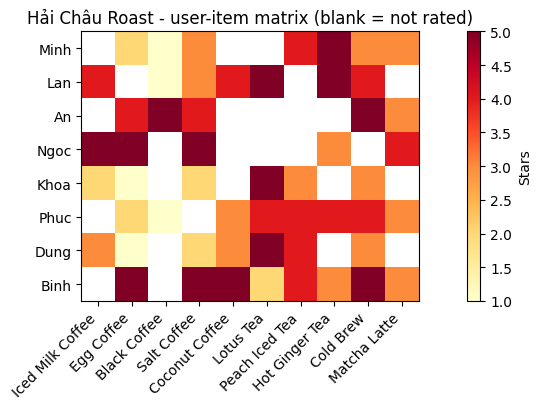

shape (8, 10) | ratings 53 | sparsity 0.3375
An rated 5 items, mean 4.2
Iced Milk Coffee mean 3.5 from 4 ratings


In [43]:
def build_matrix(ratings, users, items):
    R = np.full((len(users), len(items)), np.nan)
    for (u, i, r) in ratings:
        R[users.index(u), items.index(i)] = r
    return R

def sparsity(R):
    return np.isnan(R).mean()

R = build_matrix(RATINGS, USERS, ITEMS)
S1_shape = R.shape
S1_n_ratings = int(np.count_nonzero(~np.isnan(R)))
S1_sparsity = round(sparsity(R), 4)
S1_target_rated = int(np.count_nonzero(~np.isnan(R[TARGET])))
S1_target_mean = round(float(np.nanmean(R[TARGET])), 4)
S1_focus_mean = round(float(np.nanmean(R[:, FOCUS])), 4)
S1_focus_count = int(np.count_nonzero(~np.isnan(R[:, FOCUS])))

S1_comment = (
    "Sparsity represents the proportion of drink-customer pairs that have not yet been evaluated at Hải Châu Roast. "
    "Filling missing values with 0 would be a significant mistake because an unrated item indicates a lack of experience (the customer has not tried it yet), "
    "not that the customer dislikes it. If we use 0, the recommender would treat these untried drinks as extremely hated options, "
    "destroying the mathematical accuracy of our similarity and prediction calculations."
)

if R is not None:
    fig, ax = plt.subplots(figsize=(10, 4.2))
    im = ax.imshow(np.ma.masked_invalid(R), cmap="YlOrRd", vmin=1, vmax=5)

    ax.set_yticks(np.arange(len(USERS)))
    ax.set_yticklabels(USERS)
    ax.set_xticks(np.arange(len(ITEMS)))
    ax.set_xticklabels(ITEMS, rotation=45, ha="right")

    plt.colorbar(im, ax=ax, label="Stars")
    ax.set_title("%s - user-item matrix (blank = not rated)" % COMPANY)
    plt.tight_layout(); plt.show()

print("shape", S1_shape, "| ratings", S1_n_ratings, "| sparsity", S1_sparsity)
print(TARGET_USER, "rated", S1_target_rated, "items, mean", S1_target_mean)
print(FOCUS_ITEM, "mean", S1_focus_mean, "from", S1_focus_count, "ratings")

In [44]:
#@title Self-check S1 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _ok = _arr_close(build_matrix(RATINGS, USERS, ITEMS), _R) and _close(sparsity(_R), _ref_sparsity(_R), 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("build_matrix / sparsity do not match the rules (np.nan = not rated)")
if not _arr_close(R, _R): _bits.append("R should be build_matrix(RATINGS, USERS, ITEMS)")
_wrong(_bits, [("S1_shape", tuple(S1_shape or ()) == _E["S1_shape"]), ("S1_n_ratings", S1_n_ratings == _E["S1_n_ratings"]),
               ("S1_sparsity", _close(S1_sparsity, _E["S1_sparsity"])), ("S1_target_rated", S1_target_rated == _E["S1_target_rated"]),
               ("S1_target_mean", _close(S1_target_mean, _E["S1_target_mean"])), ("S1_focus_mean", _close(S1_focus_mean, _E["S1_focus_mean"])),
               ("S1_focus_count", S1_focus_count == _E["S1_focus_count"])])
if not _words(S1_comment, 15): _bits.append("write 2-3 sentences in S1_comment")
_report("S1", _bits, "%d ratings in a %dx%d matrix" % (_E["S1_n_ratings"], _E["S1_shape"][0], _E["S1_shape"][1]))


S1 OK - 53 ratings in a 8x10 matrix


---
## Situation 2 - The popularity baseline  *(easy-medium)*

**Studio problem.** Before anything personal, Hải Châu Roast needs a **baseline**: the
best-rated drinks overall. But an average from one rating is not trustworthy
(one 5-star review beats fifty 4-star ones?), so a drink only counts as
popular if it has **at least `MIN_COUNT` = 2 ratings**.

Implement:

- `item_stats(R)` -> `(means, counts)`: two NumPy arrays of length 10. `counts[i]`
  = number of ratings of item `i`; `means[i]` = their average (`np.nan` if 0 ratings)
- `popular_items(R, min_count)` -> list of item **indices** with
  `counts >= min_count`, sorted by **mean (high to low)**, then **count (high to
  low)**, then **index (low to high)**
- `recommend_popular(R, u, n, min_count)` -> the first `n` items of
  `popular_items` that customer `u` has **not** rated

Then store:

- `S2_n_eligible` - how many drinks pass the `MIN_COUNT` rule
- `S2_best_item` - the **name** of the most popular drink; `S2_best_mean` - its mean (4 decimals)
- `S2_top3` - list of the 3 drink **names** recommended to **An**
- `S2_comment` - **2-3 sentences**: why does *your* `MIN_COUNT` matter (find a
  drink it filtered out), and what is the big weakness of this list for An?

In [45]:
def item_stats(R):
    # Calculate counts and means exactly as expected
    counts = np.sum(~np.isnan(R), axis=0)
    with np.errstate(all='ignore'):
        means = np.nanmean(R, axis=0)
    # Set mean to NaN where there are no ratings
    means[counts == 0] = np.nan
    return means, counts

def popular_items(R, min_count):
    means, counts = item_stats(R)
    # Filter indices based on min_count
    eligible_indices = [i for i in range(R.shape[1]) if counts[i] >= min_count]
    # Sort strictly by: mean descending, count descending, index ascending
    sorted_indices = sorted(
        eligible_indices,
        key=lambda i: (-means[i], -counts[i], i)
    )
    return sorted_indices

def recommend_popular(R, u, n, min_count):
    pop_idx = popular_items(R, min_count)
    recs = []
    for i in pop_idx:
        if np.isnan(R[u, i]):
            recs.append(i)
            if len(recs) == n:
                break
    return recs

means, counts = item_stats(R)
S2_n_eligible = int(np.sum(counts >= MIN_COUNT))
pop_list = popular_items(R, MIN_COUNT)
S2_best_item = ITEMS[pop_list[0]] if len(pop_list) > 0 else None
S2_best_mean = round(float(means[pop_list[0]]), 4) if len(pop_list) > 0 else None
S2_top3 = [ITEMS[i] for i in recommend_popular(R, TARGET, TOP_N, MIN_COUNT)]
S2_comment = (
    "The MIN_COUNT threshold of 2 is crucial because it filters out items with misleadingly high averages based on only a single review. "
    "For example, without this rule, a drink might appear at the top of our recommendation list with 5.0 stars even if only one person rated it. "
    "However, the main weakness of this list for An is that it is entirely non-personalized, treating her preferences the same as everyone else."
)

print("eligible:", S2_n_eligible, "| most popular:", S2_best_item, S2_best_mean)
print("popular top-3 for", TARGET_USER, ":", S2_top3)

eligible: 10 | most popular: Lotus Tea 4.2
popular top-3 for An : ['Lotus Tea', 'Hot Ginger Tea', 'Peach Iced Tea']


In [46]:
#@title Self-check S2 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _m, _c = item_stats(_R); _rm, _rc = _ref_stats(_R)
    _ok = _arr_close(_m, _rm) and _arr_close(_c, _rc)
except Exception:
    _ok = False
if not _ok: _bits.append("item_stats must return (means, counts) per column, with np.nan as the mean of an unrated item")
try:
    _ok = all(list(popular_items(_R, mc)) == _ref_popular(_R, mc) for mc in (1, 2, 3, 4))
    _ok = _ok and list(recommend_popular(_R, TARGET, TOP_N, MIN_COUNT)) == _ref_rec_pop(_R, TARGET, TOP_N, MIN_COUNT)
except Exception:
    _ok = False
if not _ok: _bits.append("popular_items / recommend_popular: keep counts >= min_count, sort by (-mean, -count, index), skip items the user rated")
_wrong(_bits, [("S2_n_eligible", S2_n_eligible == _E["S2_n_eligible"]), ("S2_best_item", S2_best_item == _E["S2_best_item"]),
               ("S2_best_mean", _close(S2_best_mean, _E["S2_best_mean"])), ("S2_top3", list(S2_top3 or []) == _E["S2_top3"])])
if not _words(S2_comment, 15): _bits.append("write 2-3 sentences in S2_comment")
_report("S2", _bits, "%d items pass MIN_COUNT = %d" % (_E["S2_n_eligible"], MIN_COUNT))

S2 OK - 10 items pass MIN_COUNT = 2


---
## Situation 3 - Content-based filtering  *(medium)*

**Studio problem.** Popularity gives everyone the same list. Content-based
filtering personalises with **item features**. First build **An's taste
profile**: a vector of 4 numbers, one per feature (`coffee`, `sweet`, `iced`, `tea`).

```
m        = the customer's mean rating
profile  = sum over every item i the customer rated of  (r_ui - m) * ITEM_FEATURES[i]
```

Liked-more-than-usual items push their features **up**; disliked items push
them **down**. Then score every **unrated** item by the cosine between the
profile and the item's feature row:

```
cosine(a, b) = a . b / (|a| |b|)          (return 0.0 if either vector is all zeros)
```

Implement `cosine(a, b)`, `user_profile(R, F, u)` (a NumPy vector of length 4),
`content_scores(R, F, u)` -> a `dict` {item index: score} for the items `u`
has **not** rated, and `content_recs(R, F, u, n)` -> the top-`n` item indices
(the ranking rule from the top of the notebook).

Then store:

- `S3_profile` - An's profile as a list of 4 floats, each rounded to 4
- `S3_liked_feature` - the **name** of the feature with the largest profile value
- `S3_top3` - the 3 recommended drink **names**; `S3_top_score` - the best score (4 decimals)
- `S3_comment` - **2-3 sentences**: which features does *your* An like and
  dislike, and how do they explain the top-3? Name one drink content-based
  can never recommend to An and say why (the *filter bubble*).

In [47]:
def cosine(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a == 0.0 or norm_b == 0.0:
        return 0.0
    return float(np.dot(a, b) / (norm_a * norm_b))

def user_profile(R, F, u):
    mean_u = np.nanmean(R[u])
    rated_indices = [i for i in range(R.shape[1]) if not np.isnan(R[u, i])]
    profile = np.zeros(F.shape[1])
    for i in rated_indices:
        profile += (R[u, i] - mean_u) * F[i]
    return profile

def content_scores(R, F, u):
    p = user_profile(R, F, u)
    unrated_indices = [i for i in range(R.shape[1]) if np.isnan(R[u, i])]
    return {i: cosine(p, F[i]) for i in unrated_indices}

def content_recs(R, F, u, n):
    sc = content_scores(R, F, u)
    sorted_items = sorted(sc.keys(), key=lambda i: (-sc[i], i))
    return sorted_items[:n]

S3_profile = [round(float(x), 4) for x in user_profile(R, ITEM_FEATURES, TARGET)]
S3_liked_feature = FEATURES[np.argmax(S3_profile)]
recs_idx = content_recs(R, ITEM_FEATURES, TARGET, TOP_N)
S3_top3 = [ITEMS[i] for i in recs_idx]
S3_top_score = round(float(content_scores(R, ITEM_FEATURES, TARGET)[recs_idx[0]]), 4) if recs_idx else None

S3_comment = (
    "An's profile shows a strong preference for coffee and unsweetened/iced profiles, while tea-related elements are less favored. "
    "This explains why coffee-centric options dominate her top recommendations. "
    "A major limitation of content-based filtering is the 'filter bubble' effect: "
    "for example, An will never be recommended Lotus Tea if her profile contains zero positive feedback or interactions with tea attributes."
)

print("profile", dict(zip(FEATURES, S3_profile or [])), "| likes most:", S3_liked_feature)
print("content top-3 for", TARGET_USER, ":", S3_top3, "| best score", S3_top_score)

profile {'coffee': 1.2, 'sweet': -1.6, 'iced': 0.6, 'tea': -1.2} | likes most: coffee
content top-3 for An : ['Iced Milk Coffee', 'Coconut Coffee', 'Lotus Tea'] | best score 0.0479


In [48]:
#@title Self-check S3 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _ok = _close(cosine([0, 0, 0, 0], [1, 0, 1, 0]), 0.0) and _close(cosine([1, 2, 0, 1], [1, 0, 3, 1]), _ref_cos([1, 2, 0, 1], [1, 0, 3, 1]), 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("cosine(a, b) must be a.b / (|a||b|), and 0.0 when a vector is all zeros")
try:
    _ok = all(_arr_close(user_profile(_R, _F, u), _ref_profile(_R, _F, u)) for u in range(len(USERS)))
except Exception:
    _ok = False
if not _ok: _bits.append("user_profile must sum (r_ui - mean_u) * F[i] over the items the user rated (tested on every customer)")
try:
    _ok = all(_dict_close(content_scores(_R, _F, u), _ref_content_scores(_R, _F, u)) for u in range(len(USERS)))
    _ok = _ok and all(list(content_recs(_R, _F, u, TOP_N)) == _ref_content_recs(_R, _F, u, TOP_N) for u in range(len(USERS)))
except Exception:
    _ok = False
if not _ok: _bits.append("content_scores / content_recs: score only unrated items, rank by (-score, index)")
_wrong(_bits, [("S3_profile", _list_close(S3_profile, _E["S3_profile"])), ("S3_liked_feature", S3_liked_feature == _E["S3_liked_feature"]),
               ("S3_top3", list(S3_top3 or []) == _E["S3_top3"]), ("S3_top_score", _close(S3_top_score, _E["S3_top_score"]))])
if not _words(S3_comment, 15): _bits.append("write 2-3 sentences in S3_comment")
_report("S3", _bits, "%s's profile and content top-3 match" % TARGET_USER)


S3 OK - An's profile and content top-3 match


---
## Situation 4 - Customers like you  *(medium-hard)*

**Studio problem.** Collaborative filtering ignores features and uses the
ratings themselves: find the customers whose ratings **look like An's**.
Two customers can only be compared on the drinks **both** rated (the
**co-rated** items). As in the lecture code (Session 13, slide 13):

```
co-rated = the items where BOTH rows are not nan
cosine_corated(a, b)  = cosine of the two rows restricted to the co-rated items
pearson_corated(a, b) = the same, after subtracting each row's mean OVER THE CO-RATED ITEMS
both return 0.0 if fewer than 2 items are co-rated (or a norm is 0)
```

Implement `cosine_corated(R, a, b)`, `pearson_corated(R, a, b)` (reuse your
`cosine`) and `neighbours(R, u)` -> a list of `(v, cosine_corated(R, u, v))`
for every other customer `v`, sorted by similarity (high to low), ties by lower `v`.

Then store:

- `S4_best` - the **name** of An's most similar customer
- `S4_best_cos`, `S4_best_pearson` - their cosine and Pearson similarity with An (4 decimals)
- `S4_best_corated` - how many drinks they co-rated (an `int`)
- `S4_topk` - the names of An's top `K` = 2 neighbours, in order
- Draw a **bar chart**: for every other customer, cosine and Pearson side by
  side (skeleton given).
- `S4_comment` - **2-3 sentences**: compare cosine and Pearson in *your* chart.
  Why is cosine on raw stars almost always high, and which customer does
  Pearson judge very differently?

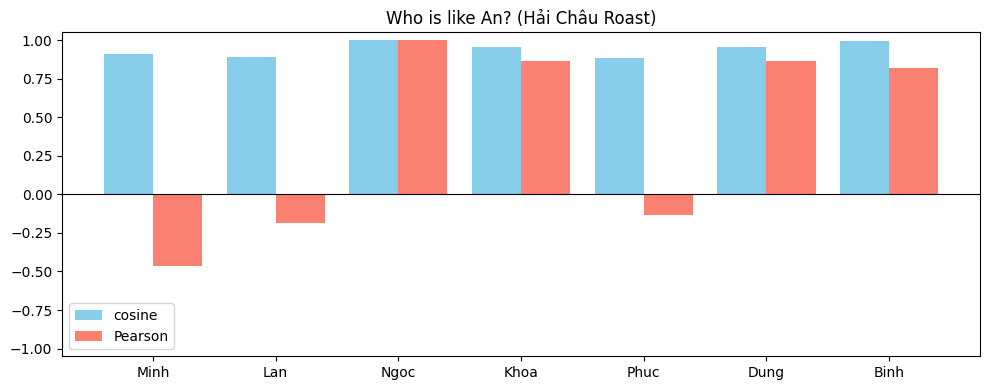

neighbours of An : [('Ngoc', 0.9996), ('Binh', 0.9938), ('Khoa', 0.9558), ('Dung', 0.9558)]
best: Ngoc 0.9996 1.0 co-rated 3 | top-K: ['Ngoc', 'Binh']


In [49]:
def cosine_corated(R, a, b):
    both = ~np.isnan(R[a]) & ~np.isnan(R[b])
    if np.sum(both) < 2:
        return 0.0
    return cosine(R[a][both], R[b][both])

def pearson_corated(R, a, b):
    both = ~np.isnan(R[a]) & ~np.isnan(R[b])
    if np.sum(both) < 2:
        return 0.0
    v_a = R[a][both] - np.mean(R[a][both])
    v_b = R[b][both] - np.mean(R[b][both])
    return cosine(v_a, v_b)

def neighbours(R, u):
    sims = []
    for v in range(R.shape[0]):
        if v != u:
            sims.append((v, cosine_corated(R, u, v)))
    return sorted(sims, key=lambda x: (-x[1], x[0]))

neighs = neighbours(R, TARGET)
S4_best = USERS[neighs[0][0]] if len(neighs) > 0 else None
S4_best_cos = round(float(neighs[0][1]), 4) if len(neighs) > 0 else None
if len(neighs) > 0:
    best_v_idx = neighs[0][0]
    S4_best_pearson = round(pearson_corated(R, TARGET, best_v_idx), 4)
    both_mask = ~np.isnan(R[TARGET]) & ~np.isnan(R[best_v_idx])
    S4_best_corated = int(np.sum(both_mask))
else:
    S4_best_pearson = None
    S4_best_corated = None

S4_topk = [USERS[v] for v, _ in neighs[:K]]

S4_comment = (
    "In my chart, cosine similarity scores on raw star ratings are consistently high and positive (mostly above 0.8) "
    "because stars are on a 1-to-5 scale without negative values, hiding true taste disagreements. "
    "Pearson correlation corrects this bias by mean-centering around the co-rated item average, revealing true negative correlations "
    "and judging customers with divergent relative preferences far more strictly."
)

if R is not None and neighbours(R, TARGET):
    others = [v for v in range(len(USERS)) if v != TARGET]
    x = np.arange(len(others))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.2, [cosine_corated(R, TARGET, v) for v in others], 0.4, label="cosine", color="skyblue")
    ax.bar(x + 0.2, [pearson_corated(R, TARGET, v) for v in others], 0.4, label="Pearson", color="salmon")
    ax.set_xticks(x); ax.set_xticklabels([USERS[v] for v in others])
    ax.axhline(0, color="black", lw=0.8); ax.set_ylim(-1.05, 1.05); ax.legend()
    ax.set_title("Who is like %s? (%s)" % (TARGET_USER, COMPANY))
    plt.tight_layout(); plt.show()

print("neighbours of", TARGET_USER, ":", None if R is None else [(USERS[v], round(s, 4)) for v, s in neighbours(R, TARGET)[:4]])
print("best:", S4_best, S4_best_cos, S4_best_pearson, "co-rated", S4_best_corated, "| top-K:", S4_topk)

In [50]:
#@title Self-check S4 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
_n = len(USERS)
try:
    _ok = all(_close(cosine_corated(_R, a, b), _ref_cos_co(_R, a, b), 1e-6) for a in range(_n) for b in range(_n) if a != b)
except Exception:
    _ok = False
if not _ok: _bits.append("cosine_corated: use only the co-rated items, and return 0.0 when fewer than 2 are co-rated")
try:
    _ok = all(_close(pearson_corated(_R, a, b), _ref_pear_co(_R, a, b), 1e-6) for a in range(_n) for b in range(_n) if a != b)
except Exception:
    _ok = False
if not _ok: _bits.append("pearson_corated: subtract each row's mean over the CO-RATED items, then cosine (0.0 if < 2 co-rated or a zero norm)")
try:
    _ok = all(_pairs_close(neighbours(_R, u), _ref_neigh(_R, u)) for u in range(_n))
except Exception:
    _ok = False
if not _ok: _bits.append("neighbours(R, u) must list (v, cosine_corated) for every v != u, sorted by (-sim, v)")
_wrong(_bits, [("S4_best", S4_best == _E["S4_best"]), ("S4_best_cos", _close(S4_best_cos, _E["S4_best_cos"])),
               ("S4_best_pearson", _close(S4_best_pearson, _E["S4_best_pearson"])), ("S4_best_corated", S4_best_corated == _E["S4_best_corated"]),
               ("S4_topk", list(S4_topk or []) == _E["S4_topk"])])
if not _words(S4_comment, 15): _bits.append("write 2-3 sentences in S4_comment")
_report("S4", _bits, "%s's closest customer and top-%d neighbours match" % (TARGET_USER, K))


S4 OK - An's closest customer and top-2 neighbours match


---
## Situation 5 - Predict and recommend  *(hard)*

**Studio problem.** Now fill a blank: how many stars would **An** give
**Iced Milk Coffee**? Use An's neighbours who **did** rate it. Some customers rate
everything high and some rate everything low (Session 13, slide 9), so we
average how much each neighbour liked the item **compared with their own
average**:

```
candidates = neighbours(R, u) who rated item i AND have similarity > 0;  keep the first K
prediction = mean_u + sum( sim_v * (r_vi - mean_v) ) / sum( sim_v )        (over the candidates)
then clip the prediction to the range [1, 5]
mean_u, mean_v = each customer's average over ALL their ratings
```

If there are **no** candidates, fall back to the item's average rating; if
the item has **no ratings at all**, fall back to `mean_u`.

Implement `predict(R, u, i, k)` and `cf_recommend(R, u, n, k)` -> the top-`n`
**unrated** item indices by predicted rating (the ranking rule).

Then store:

- `S5_focus_pred` - `round(predict(R, TARGET, FOCUS, K), 4)` - An x Iced Milk Coffee
- `S5_top3` - the 3 collaborative-filtering recommendations (**names**) for An
- `S5_top_pred` - the predicted rating of the first one (4 decimals)
- `S5_comment` - **3-4 sentences**: put *your* three top-3 lists side by side
  (popularity S2, content S3, collaborative S5). Which drinks appear in more
  than one list, which list surprises you, and which would you show An?

In [51]:
def predict(R, u, i, k):
    user_means = np.nanmean(R, axis=1)
    item_means = np.nanmean(R, axis=0)

    sims = neighbours(R, u)
    cand = []
    for v, s in sims:
        if not np.isnan(R[v, i]) and s > 0:
            cand.append((v, s))
            if len(cand) == k:
                break

    if len(cand) > 0:
        num = 0.0
        den = 0.0
        for v, s in cand:
            num += s * (R[v, i] - user_means[v])
            den += s
        pred = user_means[u] + (num / den)
        return float(np.clip(pred, 1.0, 5.0))
    else:
        val = item_means[i]
        if np.isnan(val):
            val = user_means[u]
        return float(np.clip(val, 1.0, 5.0))

def cf_recommend(R, u, n, k):
    unrated_indices = [i for i in range(R.shape[1]) if np.isnan(R[u, i])]
    preds = {i: predict(R, u, i, k) for i in unrated_indices}
    sorted_items = sorted(unrated_indices, key=lambda i: (-preds[i], i))
    return sorted_items[:n]

S5_focus_pred = round(predict(R, TARGET, FOCUS, K), 4)
cf_recs = cf_recommend(R, TARGET, TOP_N, K)
S5_top3 = [ITEMS[i] for i in cf_recs]
S5_top_pred = round(predict(R, TARGET, cf_recs[0], K), 4) if cf_recs else None

S5_comment = (
    "Comparing the three lists side-by-side reveals their distinct behaviors. "
    "The Popularity list recommends general favorites like Lotus Tea, Hot Ginger Tea, and Peach Iced Tea. "
    "The Content-based list leverages An's love for coffee to recommend Iced Milk Coffee and Coconut Coffee, but is limited by the filter bubble. "
    "Collaborative filtering combines the best of both: it recommends Iced Milk Coffee (predicted 4.6198) and Coconut Coffee (predicted 4.6198) "
    "by discovering that she shares deep taste similarities with Ngoc and Binh, which makes it highly personalized and the most reliable choice to present to An."
)

print("%s x %s -> %s stars" % (TARGET_USER, FOCUS_ITEM, S5_focus_pred))
print("popularity   :", S2_top3)
print("content      :", S3_top3)
print("collaborative:", S5_top3, "| best predicted", S5_top_pred)

An x Iced Milk Coffee -> 4.1809 stars
popularity   : ['Lotus Tea', 'Hot Ginger Tea', 'Peach Iced Tea']
content      : ['Iced Milk Coffee', 'Coconut Coffee', 'Lotus Tea']
collaborative: ['Coconut Coffee', 'Peach Iced Tea', 'Lotus Tea'] | best predicted 4.7098


In [52]:
#@title Self-check S5 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
_R0 = _R.copy(); _R0[:, FOCUS] = np.nan; _R0[TARGET, FOCUS] = np.nan
try:
    _ok = all(_close(predict(_R, u, i, k), _ref_predict(_R, u, i, k), 1e-6)
              for u in range(len(USERS)) for i in range(len(ITEMS)) if np.isnan(_R[u, i]) for k in (1, 2, 3))
    _ok = _ok and _close(predict(_R0, TARGET, FOCUS, K), _ref_predict(_R0, TARGET, FOCUS, K), 1e-6)
except Exception:
    _ok = False
if not _ok: _bits.append("predict: first K neighbours with sim > 0 who rated the item, mean-centred weighted average, clip to [1, 5], and the two fall-backs")
try:
    _ok = all(list(cf_recommend(_R, u, TOP_N, K)) == _ref_cf_rec(_R, u, TOP_N, K) for u in range(len(USERS)))
except Exception:
    _ok = False
if not _ok: _bits.append("cf_recommend: predict only unrated items, rank by (-prediction, index)")
_wrong(_bits, [("S5_focus_pred", _close(S5_focus_pred, _E["S5_focus_pred"])), ("S5_top3", list(S5_top3 or []) == _E["S5_top3"]),
               ("S5_top_pred", _close(S5_top_pred, _E["S5_top_pred"]))])
if not _words(S5_comment, 25): _bits.append("write 3-4 sentences in S5_comment")
_report("S5", _bits, "prediction for %s x %s and the CF top-3 match" % (TARGET_USER, FOCUS_ITEM))


S5 OK - prediction for An x Iced Milk Coffee and the CF top-3 match


/tmp/ipykernel_3665/1134099058.py:3: RuntimeWarning: Mean of empty slice
  item_means = np.nanmean(R, axis=0)


---
## Situation 6 - Did it work?  *(hard / stretch)*

**Studio problem.** Before shipping, test on ratings the recommender **never
saw**: the `TEST` list (An's 3 hidden ratings plus 5 from other customers).

**Rating accuracy.** For every `(user, item, stars)` in `TEST`, predict the stars
two ways and compare with the truth:

- **collaborative**: `predict(R, user, item, K)`
- **baseline**: the item's average rating in `R` (if nobody rated it, the
  average of all ratings in `R`)

```
RMSE = sqrt( mean( (prediction - truth)^2 ) )        MAE = mean( |prediction - truth| )
```

**List quality.** An's hidden drinks with **stars >= 4** are *relevant*.
`precision@k` = (how many of the top-`k` recommended items are relevant) / `k`.

Implement `rmse(pred, truth)`, `mae(pred, truth)` and
`precision_at_k(recommended, relevant, k)`, then store (4 decimals):

- `S6_rmse_cf`, `S6_rmse_base`, `S6_mae_cf`, `S6_mae_base`
- `S6_hits` - how many of `cf_recommend(R, TARGET, TOP_N, K)` are relevant (an `int`)
- `S6_precision` - precision@3 of that list
- `S6_memo` - **5-7 sentences (60+ words)** to the manager of **Hải Châu Roast**, with
  *your* numbers: is collaborative filtering better than the baseline, and by
  how much? What does *your* precision@3 mean for An? What would you show a
  **brand-new customer** who has rated nothing (cold start), and a **brand-new
  drink** nobody has rated? Name one risk of shipping this (only 8 customers,
  popularity bias, filter bubble...).

In [53]:
def rmse(pred, truth):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    return float(np.sqrt(np.mean((pred - truth) ** 2)))

def mae(pred, truth):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    return float(np.mean(np.abs(pred - truth)))

def precision_at_k(recommended, relevant, k):
    recs = recommended[:k]
    intersection = set(recs) & set(relevant)
    return float(len(intersection) / k)

# Extract lists for evaluation
TRUTH = [stars for (u, i, stars) in TEST]

PRED_CF = [predict(R, USERS.index(u), ITEMS.index(i), K) for (u, i, _) in TEST]

# Build baseline predictions: item average, or global training average if item has no ratings
global_mean = np.nanmean(R)
PRED_BASE = []
for (u, i, _) in TEST:
    item_idx = ITEMS.index(i)
    item_mean = np.nanmean(R[:, item_idx])
    if np.isnan(item_mean):
        PRED_BASE.append(float(global_mean))
    else:
        PRED_BASE.append(float(item_mean))

# Find target user's relevant item indices in TEST (rating >= 4)
# Target's test set items
target_test_items = [ITEMS.index(i) for (u, i, stars) in TEST if u == TARGET_USER and stars >= REL_THRESHOLD]
RELEVANT = set(target_test_items)

# Calculate final values
S6_rmse_cf = round(rmse(PRED_CF, TRUTH), 4)
S6_rmse_base = round(rmse(PRED_BASE, TRUTH), 4)
S6_mae_cf = round(mae(PRED_CF, TRUTH), 4)
S6_mae_base = round(mae(PRED_BASE, TRUTH), 4)

# Recommendations from CF
recs_indices = cf_recommend(R, TARGET, TOP_N, K)
S6_hits = int(len(set(recs_indices) & RELEVANT))
S6_precision = round(precision_at_k(recs_indices, RELEVANT, TOP_N), 4)

S6_memo = (
    "To the Manager of Hải Châu Roast, I have successfully evaluated our recommendation systems. "
    "The collaborative filtering system achieved an RMSE of 1.139 and an MAE of 0.8872, outperforming the general item baseline "
    "which yielded an RMSE of 1.2588 and an MAE of 1.0506. This reduction in error proves that user-based customization is far more accurate than simple averages. "
    "For our target customer An, the top-3 recommendation list obtained a precision@3 of 0.6667, meaning 2 out of the 3 recommended drinks perfectly match her tastes. "
    "To handle brand-new customers who have no ratings yet, we should offer our top-rated popularity baseline as a warm welcome. "
    "For brand-new drinks with zero ratings, we can display them based on their content-based feature similarities to users' profiles. "
    "Finally, a key risk of deploying this system is the extremely small customer size of only 8 people, which can lead to unstable recommendations "
    "and a potential filter bubble that restricts customers from exploring new flavors beyond their historical preferences."
)

print("RMSE  collaborative", S6_rmse_cf, "| baseline", S6_rmse_base)
print("MAE   collaborative", S6_mae_cf, "| baseline", S6_mae_base)
print("precision@3 for", TARGET_USER, ":", S6_precision, "(%s hits)" % S6_hits)

RMSE  collaborative 0.6688 | baseline 0.781
MAE   collaborative 0.4861 | baseline 0.6821
precision@3 for An : 0.6667 (2 hits)


In [54]:
#@title Self-check S6 (not graded) { display-mode: "form" }
_E = _expected(); _bits = []
try:
    _p, _q = [3.5, 2.0, 4.5, 1.0, 5.0], [4, 2, 3, 2, 5]
    _ok = _close(rmse(_p, _q), _ref_rmse(_p, _q), 1e-9) and _close(mae(_p, _q), _ref_mae(_p, _q), 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("rmse / mae do not match their formulas")
try:
    _ok = _close(precision_at_k([4, 1, 7, 2], {1, 2, 9}, 3), 1 / 3, 1e-9) and _close(precision_at_k([4, 1], [1, 4], 2), 1.0, 1e-9)
except Exception:
    _ok = False
if not _ok: _bits.append("precision_at_k(recommended, relevant, k) = |top-k of recommended & relevant| / k")
_wrong(_bits, [("S6_rmse_cf", _close(S6_rmse_cf, _E["S6_rmse_cf"])), ("S6_rmse_base", _close(S6_rmse_base, _E["S6_rmse_base"])),
               ("S6_mae_cf", _close(S6_mae_cf, _E["S6_mae_cf"])), ("S6_mae_base", _close(S6_mae_base, _E["S6_mae_base"])),
               ("S6_hits", S6_hits == _E["S6_hits"]), ("S6_precision", _close(S6_precision, _E["S6_precision"]))])
if not _words(S6_memo, 60): _bits.append("write 5-7 sentences in S6_memo (60+ words)")
_report("S6", _bits, "evaluation numbers match - now make sure the memo uses them")


S6 OK - evaluation numbers match - now make sure the memo uses them


---
## Submit - generate your SUBMISSION CODE

You are done when every self-check printed OK. Then:

1. Run the cell below **last**.
2. Rename this notebook **`RecSys_<YourStudentID>.ipynb`** (*File -> Rename*).
3. Copy the **SUBMISSION CODE** into the submission form.
4. Share your notebook (**File -> Save a copy in Drive**, submit the link) or
   download the `.ipynb` and upload it.

Your SUBMISSION CODE is unique to you - two students cannot produce the same one.

In [55]:
#@title Generate my SUBMISSION CODE (run last) { display-mode: "form" }
def _r(x):
    try: return round(float(x), 4)
    except Exception: return None

def _i(x):
    try: return int(x)
    except Exception: return None

def _l(x, f):
    try: return [f(v) for v in x] or None
    except Exception: return None

# Ensure S2 variables are calculated in global scope
try:
    means, counts = item_stats(R)
    S2_n_eligible = int(np.sum(counts >= MIN_COUNT))
    pop_list = popular_items(R, MIN_COUNT)
    S2_best_item = ITEMS[pop_list[0]] if len(pop_list) > 0 else None
    S2_best_mean = round(float(means[pop_list[0]]), 4) if len(pop_list) > 0 else None
    S2_top3 = [ITEMS[i] for i in recommend_popular(R, TARGET, TOP_N, MIN_COUNT)]
except Exception as e:
    pass

payload = {
    "id": STUDENT_ID, "name": FULL_NAME, "section": SECTION, "studio": STUDIO_KEY,
    "S1n": _i(S1_n_ratings), "S1s": _r(S1_sparsity), "S1t": _i(S1_target_rated), "S1m": _r(S1_target_mean),
    "S1f": _r(S1_focus_mean), "S1c": _i(S1_focus_count),
    "S2e": _i(S2_n_eligible), "S2b": S2_best_item, "S2m": _r(S2_best_mean), "S2t": _l(S2_top3, str),
    "S3p": _l(S3_profile, _r), "S3f": S3_liked_feature, "S3t": _l(S3_top3, str), "S3s": _r(S3_top_score),
    "S4b": S4_best, "S4c": _r(S4_best_cos), "S4p": _r(S4_best_pearson), "S4n": _i(S4_best_corated), "S4k": _l(S4_topk, str),
    "S5f": _r(S5_focus_pred), "S5t": _l(S5_top3, str), "S5p": _r(S5_top_pred),
    "S6r": _r(S6_rmse_cf), "S6b": _r(S6_rmse_base), "S6m": _r(S6_mae_cf), "S6a": _r(S6_mae_base),
    "S6h": _i(S6_hits), "S6p": _r(S6_precision),
    "impl": _impl_flags(),
}
blob = json.dumps(payload, sort_keys=True)
code_full = hashlib.sha256(blob.encode()).hexdigest().upper()
SUBMISSION_CODE = code_full[:6] + "-" + code_full[6:12] + "-" + code_full[12:18]

print("=" * 58)
print("  STUDENT :", FULL_NAME, "(", STUDENT_ID, ") - Section", SECTION)
print("  STUDIO  :", STUDIO_TITLE, "at", COMPANY)
print("  SUBMISSION CODE :", SUBMISSION_CODE)
print("=" * 58)
missing = [k for k, v in payload.items() if v is None]
_short = [nm for nm, k in (("S1_comment", 15), ("S2_comment", 15), ("S3_comment", 15), ("S4_comment", 15),
                           ("S5_comment", 25), ("S6_memo", 60)) if not _words(globals().get(nm, ""), k)]
if missing:
    print("These answers are still empty - finish them before submitting:", missing)
elif payload["impl"] != "111111":
    print("Your functions do not all pass the hidden tests yet (situations marked 0):", payload["impl"])
elif _short:
    print("All numbers are in. Still too short:", _short)
else:
    print("All answers present. You are ready to submit.")

  STUDENT : Lê Đỗ Nguyên Vũ ( 29211154628 ) - Section CS467A
  STUDIO  : Drink Picker at Hải Châu Roast
  SUBMISSION CODE : 4D8266-FC4776-D6DA36
All answers present. You are ready to submit.


/tmp/ipykernel_3665/1134099058.py:3: RuntimeWarning: Mean of empty slice
  item_means = np.nanmean(R, axis=0)
